# Mapa — Escorpionismo e acesso aos PESA (São Paulo, 2019–2024)

Este notebook produz **uma figura para o artigo**, com sete categorias: municípios com PESA local e seis combinações de carga acumulada de casos moderados/graves (MG) e tempo rodoviário estimado até o PESA de referência.

**Como usar:** execute as células em ordem. A base é `dados/base_analise.xlsx`, relativa à pasta onde o Jupyter foi iniciado. O arquivo final será `mapa_pesa_sp.png` (300 dpi). O título da figura fica **fora do mapa**, no texto do artigo.

**Observação:** o notebook pressupõe que o pacote `geobr` já está funcionando no seu ambiente, conforme os ajustes anteriores.

## 1. Importar bibliotecas e abrir a base

A base já contém `CARGA_MG` e `TEMPO_50`; aqui apenas combinamos essas classificações. Não recalculamos tercis nem tempos.

In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import geobr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

arquivo_base = Path("dados/base_analise.xlsx")
df = pd.read_excel(arquivo_base)

colunas = ["IBGE", "ACESSO_LOCAL", "CARGA_MG", "TEMPO_50"]
assert all(c in df.columns for c in colunas), "Faltam colunas necessárias na base."
print(f"Base carregada: {len(df)} municípios")

Base carregada: 645 municípios


## 2. Criar a classificação do mapa

A variável `CATEGORIA` combina a presença de PESA local com a classificação de carga MG (baixa, intermediária, alta) e o limite de deslocamento de 50 minutos. Os municípios com PESA local ficam em categoria própria.

In [15]:
condicoes = [
    df["ACESSO_LOCAL"].eq(1),
    df["TEMPO_50"].eq("≤50 min") & df["CARGA_MG"].eq("Baixa"),
    df["TEMPO_50"].eq("≤50 min") & df["CARGA_MG"].eq("Intermediária"),
    df["TEMPO_50"].eq("≤50 min") & df["CARGA_MG"].eq("Alta"),
    df["TEMPO_50"].eq(">50 min") & df["CARGA_MG"].eq("Baixa"),
    df["TEMPO_50"].eq(">50 min") & df["CARGA_MG"].eq("Intermediária"),
    df["TEMPO_50"].eq(">50 min") & df["CARGA_MG"].eq("Alta"),
]
rotulos = [
    "PESA local",
    "≤50 min | Baixa", "≤50 min | Intermediária", "≤50 min | Alta",
    ">50 min | Baixa", ">50 min | Intermediária", ">50 min | Alta",
]
df["CATEGORIA"] = np.select(condicoes, rotulos, default="Sem classificação")
assert (df["CATEGORIA"] != "Sem classificação").all(), "Há municípios sem classificação."
print(df["CATEGORIA"].value_counts().reindex(rotulos))

CATEGORIA
PESA local                 220
≤50 min | Baixa            142
≤50 min | Intermediária    128
≤50 min | Alta             134
>50 min | Baixa             13
>50 min | Intermediária      3
>50 min | Alta               5
Name: count, dtype: int64


## 3. Carregar a malha e unir aos indicadores

O `geobr` utiliza códigos municipais de **7 dígitos** e a sua planilha utiliza os **6 primeiros dígitos**. Por isso, a chave de junção é `COD6`. Verificamos se os 645 municípios receberam uma categoria.

In [16]:
sp = geobr.read_municipality(code_muni="SP", year=2020)

sp["COD6"] = sp["code_muni"].astype("Int64").astype(str).str[:6]
df["COD6"] = df["IBGE"].astype("Int64").astype(str).str[:6]

mapa = sp.merge(
    df[["COD6", "CATEGORIA"]],
    on="COD6", how="left", validate="one_to_one"
)

print("Municípios no mapa:", len(mapa))
print("Sem categoria:", mapa["CATEGORIA"].isna().sum())
assert len(mapa) == 645 and mapa["CATEGORIA"].notna().all(), (
    "A junção precisa ser conferida antes de desenhar o mapa."
)

Municípios no mapa: 645
Sem categoria: 0


## 4. Desenhar, identificar os cinco municípios e salvar

Esta é a **única célula de desenho**. Os rótulos são adicionados à mesma figura **antes** de salvar e exibir. Para ajustar a posição de algum nome, altere os valores em `posicoes`: primeiro horizontal (direita/esquerda), depois vertical (cima/baixo), em pontos.

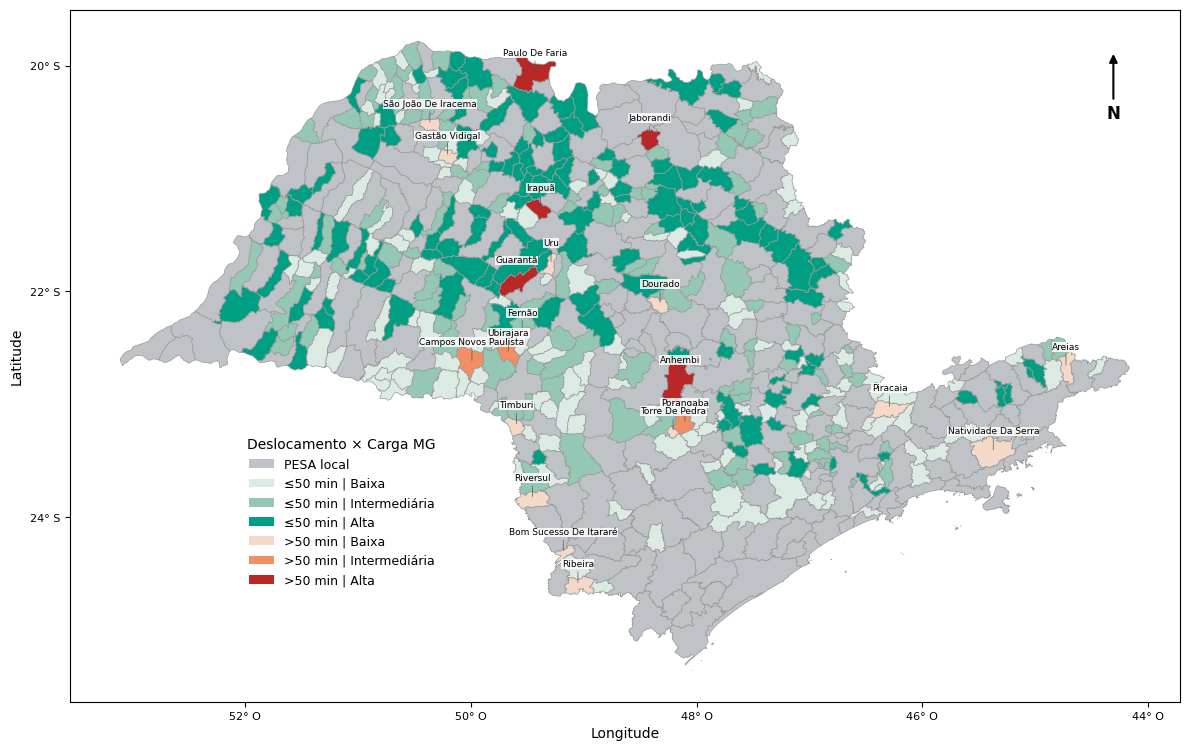

Mapa salvo: mapa_pesa_sp_geografico.png


In [17]:


import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MultipleLocator

# 1. Usar coordenadas geográficas (longitude e latitude)
mapa_geo = mapa.to_crs(epsg=4674)  # SIRGAS 2000

# 2. Cores das sete categorias
cores = {
    "PESA local": "#BFC3C7",
    "≤50 min | Baixa": "#DCEAE4",
    "≤50 min | Intermediária": "#95C8B4",
    "≤50 min | Alta": "#009F83",
    ">50 min | Baixa": "#F5D9C8",
    ">50 min | Intermediária": "#F28E63",
    ">50 min | Alta": "#B92727",
}

# 3. Criar o mapa
fig, ax = plt.subplots(figsize=(12, 9))

mapa_geo.plot(
    ax=ax,
    color=mapa_geo["CATEGORIA"].map(cores),
    edgecolor="#999999",
    linewidth=0.50
)

# 4. Identificar os 21 municípios com tempo > 50 minutos
municipios_50 = mapa_geo[
    mapa_geo["CATEGORIA"].str.startswith(">50 min", na=False)
]

assert len(municipios_50) == 21, "Verifique a classificação."

for _, municipio in municipios_50.iterrows():
    ponto = municipio.geometry.representative_point()

    ax.annotate(
        municipio["name_muni"].title(),
        xy=(ponto.x, ponto.y),
        xytext=(0, 12),
        textcoords="offset points",
        fontsize=6.5,
        ha="center",
        va="bottom",
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=0.3
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="#555555",
            linewidth=0.5
        ),
        zorder=5
    )

# 5. Legenda
legenda = [
    Patch(facecolor=cor, label=nome)
    for nome, cor in cores.items()
]

ax.legend(
    handles=legenda,
    title="Deslocamento × Carga MG",
    loc="lower left",
    bbox_to_anchor=(0.15, 0.15),
    fontsize=9,
    title_fontsize=10,
    frameon=False
)

# 6. Indicação do norte
ax.annotate(
    "N",
    xy=(0.94, 0.94),
    xytext=(0.94, 0.85),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        color="black",
        lw=1.5
    )
)

# 7. Converter graus decimais para graus
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_major_locator(MultipleLocator(2))

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{abs(x):.0f}° O")
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, pos: f"{abs(y):.0f}° S")
)

ax.set_xlabel("Longitude", fontsize=10)
ax.set_ylabel("Latitude", fontsize=10)
ax.tick_params(axis="both", labelsize=8)

# 8. Finalização e exportação
ax.set_aspect("equal")
plt.tight_layout()

plt.savefig(
    "mapa_pesa_sp_geografico.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mapa salvo: mapa_pesa_sp_geografico.png")


### Título e nota sugeridos para o artigo

**Figura 1 —** Distribuição dos municípios segundo o número acumulado de casos moderados/graves de escorpionismo e o tempo rodoviário estimado até o PESA de referência. Estado de São Paulo, 2019–2024.

**Nota:** Carga MG baixa: 0–2 casos; intermediária: 3–6; alta: ≥7, no período de 2019–2024. O tempo representa deslocamento rodoviário estimado a partir da sede municipal, e não o tempo efetivamente observado até a administração do antiveneno. Municípios com PESA local foram representados separadamente.


In [22]:
'Municípios com tempo >50min'
df.loc[df['TEMPO_50']=='>50 min',['REGIAO','MUNI', 'TEMPO','CATEGORIA']]

,REGIAO,MUNI,TEMPO,CATEGORIA
31,ARARAQUARA,DOURADO,54.100000,>50 min | Baixa
63,ASSIS,TIMBURI,57.500000,>50 min | Baixa
67,BARRETOS,JABORANDI,57.600000,>50 min | Alta
101,BAURU,URU,56.300000,>50 min | Baixa
103,BOTUCATU,ANHEMBI,54.900000,>50 min | Alta
117,BOTUCATU,PORANGABA,63.500000,>50 min | Intermediária
123,BOTUCATU,TORRE DE PEDRA,58.200000,>50 min | Baixa
141,CAMPINAS,PIRACAIA,70.800000,>50 min | Baixa
162,ITAPEVA,BOM SUCESSO DE ITARARE,60.200000,>50 min | Baixa
165,ITAPEVA,RIBEIRA,59.100000,>50 min | Baixa
